Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report
from PIL import Image
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import cv2 as cv
from google.colab import drive

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram

from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA


import seaborn as sns

drive.mount('/content/drive')

Mounted at /content/drive


Data Preperation

In [16]:
data = pd.read_csv('/content/drive/MyDrive/Colab/CY08MSP_TCH_QQQ.csv')
datas = pd.read_csv('/content/drive/MyDrive/Colab/CY09_MS_TCH_PUF.csv')
list(datas.head())

/tmp/ipykernel_604/1576255118.py:1: DtypeWarning: Columns (403,417,418,419,420,421,424,430,431,432) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('/content/drive/MyDrive/Colab/CY08MSP_TCH_QQQ.csv')
/tmp/ipykernel_604/1576255118.py:2: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  datas = pd.read_csv('/content/drive/MyDrive/Colab/CY09_MS_TCH_PUF.csv')


['CNT',
 'CNTRYID',
 'CNTSCHID',
 'CNTTCHID',
 'CYC',
 'NatCen',
 'STRATUM',
 'SUBNATIO',
 'REGION',
 'OECD',
 'Option_FLA',
 'Option_FLASCI',
 'LANGTEST_QQQ',
 'TC002Q01NA',
 'TC007Q01NA_Q',
 'TC007Q02NA_Q',
 'TC007Q03DA_Q',
 'TC007Q04DA_Q',
 'TC007Q05DA_Q',
 'TC013Q01NA',
 'TC015Q01NA',
 'TC018Q01NA',
 'TC018Q01NB',
 'TC018Q02NA',
 'TC018Q02NB',
 'TC018Q03NA',
 'TC018Q03NB',
 'TC018Q04NA',
 'TC018Q04NB',
 'TC018Q05NA',
 'TC018Q05NB',
 'TC018Q06NA',
 'TC018Q06NB',
 'TC018Q07NA',
 'TC018Q07NB',
 'TC018Q08NA',
 'TC018Q08NB',
 'TC018Q09NA',
 'TC018Q09NB',
 'TC018Q10NA',
 'TC018Q10NB',
 'TC018Q11NA',
 'TC018Q11NB',
 'TC018Q12DA',
 'TC018Q12DB',
 'TC018Q13DA',
 'TC018Q13DB',
 'TC020Q01NA',
 'TC020Q02NA',
 'TC020Q03NA',
 'TC020Q04NA',
 'TC020Q05NA',
 'TC020Q07JA',
 'TC020Q08JA',
 'TC020Q09JA',
 'TC020Q11JA',
 'TC020Q14JA',
 'TC021Q01NA',
 'TC033Q04NA',
 'TC033Q05NA',
 'TC033Q06NA',
 'TC033Q08NA',
 'TC034Q01NA',
 'TC034Q06NA',
 'TC034Q09DA',
 'TC034Q10DA',
 'TC037Q01NA',
 'TC037Q02NA',
 'TC0

In [17]:
print(datas.shape)

print(data.shape)

(25776, 578)
(68054, 433)


In [18]:
# List of target variables extracted from univaraite d.comm.xlsx
target_variables = [
    'CNT', 'CNTRYID', 'NatCen',
    'SUBNATIO', 'REGION', 'TCHTYPE', 'TC001Q01NA', 'TC002Q01NA',
    'TC211Q01JA', 'TC007Q01NA', 'TC007Q02NA', 'TC215Q01JA', 'TC216Q01JA',
    'TC216Q02JA', 'TC216Q03JA', 'TC216Q04JA', 'TC216Q05JA', 'TC216Q06JA',
    'TC216Q07JA', 'TC216Q08JA', 'TC218Q01JA', 'TC014Q01HA', 'TC045Q01NA',
    'TC045Q01NB', 'TC045Q02NA', 'TC045Q02NB', 'TC045Q04NA', 'TC045Q04NB',
    'TC045Q05NA', 'TC045Q05NB', 'TC045Q06NA', 'TC045Q06NB', 'TC045Q08NA',
    'TC045Q08NB', 'TC045Q09NA', 'TC045Q09NB', 'TC045Q10NA', 'TC045Q10NB',
    'TC045Q15NA', 'TC045Q15NB', 'TC045Q18HA', 'TC045Q18HB', 'TC021Q01NA',
    'TC185Q01HA', 'TC185Q02HA', 'TC185Q04HA', 'TC185Q06HA', 'TC185Q08HA',
    'TC185Q09HA', 'TC185Q10HA', 'TC185Q15HA', 'TC185Q18HA', 'TC219Q01JA',
    'TC046Q04NA', 'TC046Q05NA', 'TC046Q06NA', 'TC046Q07NA', 'TC198Q01HA',
    'TC198Q02HA', 'TC198Q04HA', 'TC198Q05HA', 'TC198Q06HA', 'TC198Q07HA',
    'TC198Q08HA', 'TC198Q09HA', 'TC198Q10HA', 'TC170Q01HA', 'TC170Q02HA',
    'TC170Q03HA', 'TC170Q04HA', 'TC170Q05HA', 'TC170Q06JA', 'TC170Q07JA',
    'TC020Q01NA', 'TC020Q02NA', 'TC020Q03NA', 'TC020Q04NA', 'TC020Q05NA',
    'TC020Q06NA', 'TC020Q07JA', 'TC020Q08JA', 'TC020Q09JA', 'TC020Q10JA',
    'TC020Q11JA', 'TC020Q12JA', 'TC020Q13JA', 'TC020Q14JA', 'TC233Q01JA',
    'TC233Q02JA', 'TC233Q05JA', 'TC233Q06JA', 'TC199Q01HA', 'TC199Q02HA',
    'TC199Q03HA', 'TC199Q04HA', 'TC199Q05HA', 'TC199Q06HA', 'TC199Q07HA',
    'TC199Q08HA', 'TC199Q09HA', 'TC199Q10HA', 'TC199Q11HA', 'TC199Q12HA',
    'TC196Q02HA', 'TC196Q03HA', 'TC196Q04HA', 'TC196Q05HA', 'TC234Q01JA',
    'TC234Q02JA', 'TC234Q03JA', 'TC234Q04JA', 'TC234Q05JA', 'TC234Q06JA',
    'TC234Q08JA', 'TC234Q09JA', 'TC235Q01JA', 'TC235Q02JA', 'TC235Q03JA',
    'TC235Q04JA', 'TC235Q05JA', 'TC235Q06JA', 'TC236Q01JA', 'TC236Q02JA',
    'TC236Q03JA', 'TC236Q04JA', 'TC236Q05JA', 'TC236Q06JA', 'TC236Q07JA',
    'TC237Q01JA', 'TC237Q02JA', 'TC237Q03JA', 'TC237Q04JA', 'TC237Q05JA',
    'TC237Q06JA', 'TC238Q01JA', 'TC238Q02JA', 'TC238Q03JA', 'TC238Q04JA',
    'TC238Q05JA', 'TC241Q01JA', 'TC241Q02JA', 'TC241Q03JA', 'TC241Q04JA',
    'TC241Q05JA', 'TC243Q01JA', 'TC243Q02JA', 'TC243Q03JA', 'TC243Q04JA',
    'TC243Q05JA', 'TC243Q06JA', 'TC245Q01JA', 'TC246Q01JA', 'TC246Q02JA',
    'TC246Q03JA', 'TC246Q04JA', 'TC246Q05JA', 'TC246Q06JA', 'TC246Q07JA',
    'TC247Q01JA', 'TC247Q02JA', 'TC247Q03JA', 'TC247Q04JA', 'TC248Q01JA',
    'TC249Q01JA', 'TC250Q01JA', 'TC251Q01JA', 'TC251Q02JA', 'TC251Q03JA',
    'TC251Q04JA', 'TC251Q05JA', 'TC251Q06JA', 'TC251Q07JA', 'TC253Q01JA',
    'TC253Q02JA', 'TC253Q03JA', 'TC253Q04JA', 'TC253Q05JA', 'TC253Q06JA',
    'TC253Q07JA', 'TC254Q01JA', 'TC254Q02JA', 'TC254Q03JA', 'TC254Q04JA',
    'TC255Q01JA', 'TC255Q02JA', 'TC255Q03JA', 'TC255Q04JA', 'TC255Q05JA',
    'TC255Q06JA', 'TC255Q07JA', 'TC255Q08JA', 'TC255Q09JA', 'TC256Q01JA',
    'TC256Q02JA', 'TC256Q03JA', 'TC256Q04JA', 'TC256Q05JA', 'TC256Q06JA',
    'TC256Q07JA', 'TC256Q08JA', 'TC256Q09JA', 'TC256Q10JA', 'TC257Q01JA',
    'TC258Q01JA', 'TC259Q01JA', 'TC260Q01JA', 'TC260Q02JA', 'TC260Q03JA',
    'TC260Q04JA', 'TC260Q05JA'
]

# Create teachers dataframe ignoring columns that aren't present in the data dictionary
existing_columns = [col for col in target_variables if col in datas.columns]
teachers = datas[existing_columns].copy()

#shape of new dataframe
print(f"New DataFrame shape: {teachers.shape}")

New DataFrame shape: (25776, 63)


In [19]:
#Basic check for rows & columns

print("Dataset shape:", teachers.shape)

print("Number of rows:", teachers.shape[0])
print("Number of columns:", teachers.shape[1])
print(teachers.isna().sum())

Dataset shape: (25776, 63)
Number of rows: 25776
Number of columns: 63
CNT           0
CNTRYID       0
NatCen        0
SUBNATIO      0
REGION        0
             ..
TC199Q08HA    0
TC199Q09HA    0
TC199Q10HA    0
TC199Q11HA    0
TC199Q12HA    0
Length: 63, dtype: int64


In [20]:
categorical_columns = [
    "TC001Q01NA", "TC211Q01JA", "TC218Q01JA", "TC014Q01HA", "TC045Q01NA",
    "TC045Q01NB", "TC045Q02NA", "TC045Q02NB", "TC045Q04NA", "TC045Q04NB",
    "TC045Q05NA", "TC045Q05NB", "TC045Q06NA", "TC045Q06NB", "TC045Q08NA",
    "TC045Q08NB", "TC045Q09NA", "TC045Q09NB", "TC045Q10NA", "TC045Q10NB",
    "TC045Q15NA", "TC045Q15NB", "TC045Q18HA", "TC045Q18HB", "TC021Q01NA",
    "TC185Q01HA", "TC185Q02HA", "TC185Q04HA", "TC185Q06HA", "TC185Q08HA",
    "TC185Q09HA", "TC185Q10HA", "TC185Q15HA", "TC185Q18HA", "TC219Q01JA",
    "TC046Q04NA", "TC046Q05NA", "TC046Q06NA", "TC046Q07NA", "TC198Q01HA",
    "TC198Q02HA", "TC198Q04HA", "TC198Q05HA", "TC198Q06HA", "TC198Q07HA",
    "TC198Q08HA", "TC198Q09HA", "TC198Q10HA", "TC170Q01HA", "TC170Q02HA",
    "TC170Q03HA", "TC170Q04HA", "TC170Q05HA", "TC170Q06JA", "TC170Q07JA",
    "TC020Q01NA", "TC020Q02NA", "TC020Q03NA", "TC020Q04NA", "TC020Q05NA",
    "TC020Q06NA", "TC020Q07JA", "TC020Q08JA", "TC020Q09JA", "TC020Q10JA",
    "TC020Q11JA", "TC020Q12JA", "TC020Q13JA", "TC020Q14JA", "TC233Q01JA",
    "TC233Q02JA", "TC233Q05JA", "TC233Q06JA", "TC199Q01HA", "TC199Q02HA",
    "TC199Q03HA", "TC199Q04HA", "TC199Q05HA", "TC199Q06HA", "TC199Q07HA",
    "TC199Q08HA", "TC199Q09HA", "TC199Q10HA", "TC199Q11HA", "TC199Q12HA",
    "TC196Q02HA", "TC196Q03HA", "TC196Q04HA", "TC196Q05HA", "TC234Q01JA",
    "TC234Q02JA", "TC234Q03JA", "TC234Q04JA", "TC234Q05JA", "TC234Q06JA",
    "TC234Q08JA", "TC234Q09JA", "TC235Q01JA", "TC235Q02JA", "TC235Q03JA",
    "TC235Q04JA", "TC235Q05JA", "TC235Q06JA", "TC236Q01JA", "TC236Q02JA",
    "TC236Q03JA", "TC236Q04JA", "TC236Q05JA", "TC236Q06JA", "TC236Q07JA",
    "TC237Q01JA", "TC237Q02JA", "TC237Q03JA", "TC237Q04JA", "TC237Q05JA",
    "TC237Q06JA", "TC238Q01JA", "TC238Q02JA", "TC238Q03JA", "TC238Q04JA",
    "TC238Q05JA", "TC241Q01JA", "TC241Q02JA", "TC241Q03JA", "TC241Q04JA",
    "TC241Q05JA", "TC243Q01JA", "TC243Q02JA", "TC243Q03JA", "TC243Q04JA",
    "TC243Q05JA", "TC243Q06JA", "TC246Q01JA", "TC246Q02JA", "TC246Q03JA",
    "TC246Q04JA", "TC246Q05JA", "TC246Q06JA", "TC246Q07JA", "TC247Q01JA",
    "TC247Q02JA", "TC247Q03JA", "TC247Q04JA", "TC248Q01JA", "TC250Q01JA",
    "TC251Q01JA", "TC251Q02JA", "TC251Q03JA", "TC251Q04JA", "TC251Q05JA",
    "TC251Q06JA", "TC251Q07JA", "TC253Q01JA", "TC253Q02JA", "TC253Q03JA",
    "TC253Q04JA", "TC253Q05JA", "TC253Q06JA", "TC253Q07JA", "TC254Q01JA",
    "TC254Q02JA", "TC254Q03JA", "TC254Q04JA", "TC255Q01JA", "TC255Q02JA",
    "TC255Q03JA", "TC255Q04JA", "TC255Q05JA", "TC255Q06JA", "TC255Q07JA",
    "TC255Q08JA", "TC255Q09JA", "TC256Q01JA", "TC256Q02JA", "TC256Q03JA",
    "TC256Q04JA", "TC256Q05JA", "TC256Q06JA", "TC256Q07JA", "TC256Q08JA",
    "TC256Q09JA", "TC256Q10JA", "TC260Q01JA", "TC260Q02JA", "TC260Q03JA",
    "TC260Q04JA", "TC260Q05JA"
]

# Ensure we only pick columns that actually exist 'teachers' DataFrame
# (This prevents a KeyError if your DataFrame is missing any of these columns)
cat_cols= [col for col in categorical_columns if col in teachers.columns]

quant_cols = [col for col in teachers.columns if col not in cat_cols]
# Filter the DataFrame
cat_teachers = teachers[cat_cols]
quant_teachers = teachers[quant_cols]

# display first few rows and shape
print(cat_teachers.head())
print(f"Teachers shape: {teachers.shape}")
print(f"Cat_teachers shape: {cat_teachers.shape}")
print(f"Quant_teachers shape: {quant_teachers.shape}")

   TC211Q01JA  TC045Q01NA  TC045Q01NB  TC045Q02NA  TC045Q02NB  TC045Q04NA  \
0           1           2           2           1           1           1   
1           1           1           2           2           1           2   
2           1           1           1           1           2           1   
3           1           2           2           1           1           1   
4           1           1           2           1           1           1   

   TC045Q04NB  TC045Q05NA  TC045Q05NB  TC045Q06NA  TC045Q06NB  TC045Q08NA  \
0           2           1           2           1           1           1   
1           1           2           1           2           1           2   
2           2           1           2           1           2           1   
3           1           2           1           1           2           2   
4           2           1           1           1           2           1   

   TC045Q08NB  TC045Q09NA  TC045Q09NB  TC045Q10NA  TC045Q10NB  TC045Q15NA 

In [21]:
# Replace labeled missing values with a blank value
missing_placeholders = [95, 96, 97, 98, 99]
# if NA is better replace "" with np.nan
cat_teachers = cat_teachers.replace(missing_placeholders, "")

print(cat_teachers.head())

print(cat_teachers.isna().sum())

   TC211Q01JA  TC045Q01NA  TC045Q01NB  TC045Q02NA  TC045Q02NB  TC045Q04NA  \
0           1           2           2           1           1           1   
1           1           1           2           2           1           2   
2           1           1           1           1           2           1   
3           1           2           2           1           1           1   
4           1           1           2           1           1           1   

   TC045Q04NB  TC045Q05NA  TC045Q05NB  TC045Q06NA  TC045Q06NB  TC045Q08NA  \
0           2           1           2           1           1           1   
1           1           2           1           2           1           2   
2           2           1           2           1           2           1   
3           1           2           1           1           2           2   
4           2           1           1           1           2           1   

   TC045Q08NB  TC045Q09NA  TC045Q09NB  TC045Q10NA  TC045Q10NB  TC045Q15NA 

In [22]:
# Replace labeled missing values with a blank value
missing_placeholders = [99, 98,97,96,95, 999,998,997,996,995, 9999, 9998,9997,9996,9995, 99999,99998,99997,99996,99995, 999999,999998,999997,999996,999995]
# if NA is better replace "" with np.nan
quant_teachers = quant_teachers.replace(missing_placeholders, "")

print(quant_teachers.head()) #google gemini was used

print(quant_teachers.isna().sum())

   CNT CNTRYID  NatCen  SUBNATIO  REGION TC002Q01NA
0  AUS      36    3600    360000    3600          2
1  AUS      36    3600    360000    3600          4
2  AUS      36    3600    360000    3600          1
3  AUS      36    3600    360000    3600          4
4  AUS      36    3600    360000    3600          4
CNT           0
CNTRYID       0
NatCen        0
SUBNATIO      0
REGION        0
TC002Q01NA    0
dtype: int64


In [24]:
quant_teachers.to_csv("quant_teacher.csv")
cat_teachers.to_csv("cat_teachers.csv")

df=pd.concat([quant_teachers, cat_teachers])
list(df.head())

['CNT',
 'CNTRYID',
 'NatCen',
 'SUBNATIO',
 'REGION',
 'TC002Q01NA',
 'TC211Q01JA',
 'TC045Q01NA',
 'TC045Q01NB',
 'TC045Q02NA',
 'TC045Q02NB',
 'TC045Q04NA',
 'TC045Q04NB',
 'TC045Q05NA',
 'TC045Q05NB',
 'TC045Q06NA',
 'TC045Q06NB',
 'TC045Q08NA',
 'TC045Q08NB',
 'TC045Q09NA',
 'TC045Q09NB',
 'TC045Q10NA',
 'TC045Q10NB',
 'TC045Q15NA',
 'TC045Q15NB',
 'TC045Q18HA',
 'TC045Q18HB',
 'TC021Q01NA',
 'TC185Q01HA',
 'TC185Q02HA',
 'TC185Q04HA',
 'TC185Q06HA',
 'TC185Q08HA',
 'TC185Q09HA',
 'TC185Q10HA',
 'TC185Q15HA',
 'TC185Q18HA',
 'TC046Q04NA',
 'TC046Q05NA',
 'TC046Q06NA',
 'TC046Q07NA',
 'TC020Q01NA',
 'TC020Q02NA',
 'TC020Q03NA',
 'TC020Q04NA',
 'TC020Q05NA',
 'TC020Q07JA',
 'TC020Q08JA',
 'TC020Q09JA',
 'TC020Q11JA',
 'TC020Q14JA',
 'TC199Q01HA',
 'TC199Q02HA',
 'TC199Q03HA',
 'TC199Q04HA',
 'TC199Q05HA',
 'TC199Q06HA',
 'TC199Q07HA',
 'TC199Q08HA',
 'TC199Q09HA',
 'TC199Q10HA',
 'TC199Q11HA',
 'TC199Q12HA']

Merge

In [6]:
#df = pd.read_csv('/content/drive/MyDrive/Colab/teacher.csv')
list(df.head())

['Unnamed: 0',
 'X',
 'CNT',
 'CNTRYID',
 'NatCen',
 'SUBNATIO',
 'REGION',
 'TCHTYPE',
 'TC002Q01NA',
 'TC007Q01NA',
 'TC007Q02NA',
 'TC215Q01JA',
 'TC216Q01JA',
 'TC216Q02JA',
 'TC216Q03JA',
 'TC216Q04JA',
 'TC216Q05JA',
 'TC216Q06JA',
 'TC216Q07JA',
 'TC216Q08JA',
 'TC245Q01JA',
 'TC249Q01JA',
 'TC257Q01JA',
 'TC258Q01JA',
 'TC259Q01JA',
 '...25',
 'TC001Q01NA',
 'TC211Q01JA',
 'TC218Q01JA',
 'TC014Q01HA',
 'TC045Q01NA',
 'TC045Q01NB',
 'TC045Q02NA',
 'TC045Q02NB',
 'TC045Q04NA',
 'TC045Q04NB',
 'TC045Q05NA',
 'TC045Q05NB',
 'TC045Q06NA',
 'TC045Q06NB',
 'TC045Q08NA',
 'TC045Q08NB',
 'TC045Q09NA',
 'TC045Q09NB',
 'TC045Q10NA',
 'TC045Q10NB',
 'TC045Q15NA',
 'TC045Q15NB',
 'TC045Q18HA',
 'TC045Q18HB',
 'TC021Q01NA',
 'TC185Q01HA',
 'TC185Q02HA',
 'TC185Q04HA',
 'TC185Q06HA',
 'TC185Q08HA',
 'TC185Q09HA',
 'TC185Q10HA',
 'TC185Q15HA',
 'TC185Q18HA',
 'TC219Q01JA',
 'TC046Q04NA',
 'TC046Q05NA',
 'TC046Q06NA',
 'TC046Q07NA',
 'TC198Q01HA',
 'TC198Q02HA',
 'TC198Q04HA',
 'TC198Q05HA',
 '

Univariate Analysis

In [7]:
df.head()

,Unnamed: 0,X,CNT,CNTRYID,NatCen,SUBNATIO,REGION,TCHTYPE,TC002Q01NA,TC007Q01NA,...,TC256Q06JA,TC256Q07JA,TC256Q08JA,TC256Q09JA,TC256Q10JA,TC260Q01JA,TC260Q02JA,TC260Q03JA,TC260Q04JA,TC260Q05JA
0,1,0,QAZ,31,3100,310000,3100,1,61.0,32.0,...,NaN,NaN,NaN,NaN,NaN,4.0,NaN,3.0,NaN,NaN
1,2,1,QAZ,31,3100,310000,3100,2,62.0,42.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2,QAZ,31,3100,310000,3100,2,67.0,26.0,...,1.0,1.0,1.0,1.0,1.0,4.0,2.0,4.0,4.0,2.0
3,4,3,QAZ,31,3100,310000,3100,2,66.0,28.0,...,1.0,1.0,1.0,1.0,1.0,4.0,1.0,4.0,3.0,1.0
4,5,4,QAZ,31,3100,310000,3100,1,58.0,30.0,...,4.0,5.0,5.0,4.0,4.0,4.0,2.0,3.0,2.0,2.0


In [9]:
target_var = ["CNT", "CNTRYID", "NatCen", "SUBNATIO", "REGION", "TCHTYPE", 'TC001Q01NA', "TC002Q01NA","TC258Q01JA",
"TC259Q01JA","TC260Q01JA","TC260Q02JA","TC260Q03JA","TC260Q04JA", "TC260Q05JA", "TC045Q05NA",
"TC045Q05NB", "TC007Q01NA", "TC007Q02NA", "TC249Q01JA","TC250Q01JA","TC251Q01JA","TC251Q02JA","TC251Q03JA","TC251Q04JA",
"TC251Q05JA",'TC251Q06JA',"TC251Q07JA","TC237Q01JA","TC237Q02JA","TC237Q03JA",
"TC237Q04JA","TC237Q05JA", "TC237Q06JA","TC238Q01JA","TC238Q02JA","TC238Q03JA","TC238Q04JA",
"TC238Q05JA","TC241Q01JA","TC241Q02JA","TC241Q03JA","TC241Q04JA","TC241Q05JA","TC243Q01JA",
"TC243Q02JA","TC243Q03JA","TC243Q04JA","TC243Q05JA","TC243Q06JA","TC245Q01JA","TC246Q01JA",
"TC246Q02JA","TC246Q03JA","TC246Q04JA","TC246Q05JA","TC246Q06JA","TC246Q07JA"
]

target_var

['CNT',
 'CNTRYID',
 'NatCen',
 'SUBNATIO',
 'REGION',
 'TCHTYPE',
 'TC001Q01NA',
 'TC002Q01NA',
 'TC258Q01JA',
 'TC259Q01JA',
 'TC260Q01JA',
 'TC260Q02JA',
 'TC260Q03JA',
 'TC260Q04JA',
 'TC260Q05JA',
 'TC045Q05NA',
 'TC045Q05NB',
 'TC007Q01NA',
 'TC007Q02NA',
 'TC249Q01JA',
 'TC250Q01JA',
 'TC251Q01JA',
 'TC251Q02JA',
 'TC251Q03JA',
 'TC251Q04JA',
 'TC251Q05JA',
 'TC251Q06JA',
 'TC251Q07JA',
 'TC237Q01JA',
 'TC237Q02JA',
 'TC237Q03JA',
 'TC237Q04JA',
 'TC237Q05JA',
 'TC237Q06JA',
 'TC238Q01JA',
 'TC238Q02JA',
 'TC238Q03JA',
 'TC238Q04JA',
 'TC238Q05JA',
 'TC241Q01JA',
 'TC241Q02JA',
 'TC241Q03JA',
 'TC241Q04JA',
 'TC241Q05JA',
 'TC243Q01JA',
 'TC243Q02JA',
 'TC243Q03JA',
 'TC243Q04JA',
 'TC243Q05JA',
 'TC243Q06JA',
 'TC245Q01JA',
 'TC246Q01JA',
 'TC246Q02JA',
 'TC246Q03JA',
 'TC246Q04JA',
 'TC246Q05JA',
 'TC246Q06JA',
 'TC246Q07JA']

In [10]:
holder = [col for col in target_var if col in df.columns]
target = df[holder].copy()
#target_cols = [col for col in target_var if col in teacher_final.columns]

#targets = teacher_final[target_cols]

# display first few rows and shape
print(target.head())
print(f"Target columns shape: {target.shape}")

   CNT  CNTRYID  NatCen  SUBNATIO  REGION  TCHTYPE  TC001Q01NA  TC002Q01NA  \
0  QAZ       31    3100    310000    3100        1         1.0        61.0   
1  QAZ       31    3100    310000    3100        2         1.0        62.0   
2  QAZ       31    3100    310000    3100        2         1.0        67.0   
3  QAZ       31    3100    310000    3100        2         1.0        66.0   
4  QAZ       31    3100    310000    3100        1         1.0        58.0   

   TC258Q01JA  TC259Q01JA  ...  TC243Q05JA  TC243Q06JA  TC245Q01JA  \
0         9.0         9.0  ...         NaN         NaN        41.0   
1         NaN         NaN  ...         NaN         NaN        28.0   
2        10.0        10.0  ...         1.0         1.0        75.0   
3        10.0        10.0  ...         2.0         2.0        23.0   
4         8.0         5.0  ...         2.0         2.0        19.0   

   TC246Q01JA  TC246Q02JA  TC246Q03JA  TC246Q04JA  TC246Q05JA  TC246Q06JA  \
0         4.0         4.0        

In [11]:
pd.options.display.max_columns = None
target.describe()

,CNTRYID,NatCen,SUBNATIO,REGION,TCHTYPE,TC001Q01NA,TC002Q01NA,TC258Q01JA,TC259Q01JA,TC260Q01JA,TC260Q02JA,TC260Q03JA,TC260Q04JA,TC260Q05JA,TC045Q05NA,TC045Q05NB,TC007Q01NA,TC007Q02NA,TC249Q01JA,TC250Q01JA,TC251Q01JA,TC251Q02JA,TC251Q03JA,TC251Q04JA,TC251Q05JA,TC251Q06JA,TC251Q07JA,TC237Q01JA,TC237Q02JA,TC237Q03JA,TC237Q04JA,TC237Q05JA,TC237Q06JA,TC238Q01JA,TC238Q02JA,TC238Q03JA,TC238Q04JA,TC238Q05JA,TC241Q01JA,TC241Q02JA,TC241Q03JA,TC241Q04JA,TC241Q05JA,TC243Q01JA,TC243Q02JA,TC243Q03JA,TC243Q04JA,TC243Q05JA,TC243Q06JA,TC245Q01JA,TC246Q01JA,TC246Q02JA,TC246Q03JA,TC246Q04JA,TC246Q05JA,TC246Q06JA,TC246Q07JA
count,68054.000000,68054.000000,6.805400e+04,68054.000000,68054.000000,64852.000000,67143.000000,54474.000000,54453.000000,53997.000000,51759.000000,53800.000000,53659.000000,51840.000000,68054.000000,68054.000000,67059.000000,66912.000000,53963.000000,54163.000000,53541.000000,53367.000000,53250.000000,53360.000000,53378.000000,53318.000000,53558.000000,50224.000000,50134.000000,50119.000000,50127.000000,50303.000000,50324.000000,53860.000000,53808.000000,53804.000000,53774.000000,53843.000000,54026.000000,53959.000000,53907.000000,53941.000000,53934.000000,53958.000000,53706.000000,53623.000000,53753.000000,53764.000000,53705.000000,52622.000000,53839.000000,53854.000000,53875.000000,53910.000000,53781.000000,53438.000000,53748.000000
mean,357.794428,35779.699665,3.577967e+06,35779.722382,1.770594,1.403951,43.257957,7.896575,7.977908,3.369521,1.849302,3.179108,2.594122,1.678221,0.600494,0.469759,9.336912,16.588968,18.514686,1.805088,1.805401,1.953117,1.812357,1.863418,2.053899,1.863517,2.421711,1.836692,1.825927,1.786827,1.780936,3.120709,3.166441,3.139696,3.020424,3.106182,3.048518,3.301729,3.148299,3.270353,3.407498,3.230771,3.212686,2.880351,2.542751,2.624322,2.697505,2.443308,2.246532,33.158432,2.808800,3.276488,3.247239,3.048952,3.211692,2.223642,2.812774
std,260.164624,26016.883197,2.601683e+06,26016.163577,0.420454,0.490692,10.753447,2.006055,2.040373,0.635225,0.768358,0.677802,0.866067,0.807756,0.490999,0.500265,8.911260,10.353930,155.241497,0.396136,0.979253,0.970373,0.912983,0.943071,0.938205,0.927697,1.227393,0.715658,0.712129,0.724356,0.722188,0.795637,0.768390,0.679598,0.739898,0.710553,0.774340,0.663460,0.740497,0.687453,0.575497,0.644209,0.649580,0.771376,0.820920,0.770853,0.744047,0.854000,0.881560,65.346191,1.009905,0.701684,0.708494,0.762023,0.770564,0.978541,0.977037
min,31.000000,3100.000000,3.100000e+05,3100.000000,1.000000,1.000000,20.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,76.000000,7600.000000,7.600000e+05,7604.000000,2.000000,1.000000,35.000000,7.000000,7.000000,3.000000,1.000000,3.000000,2.000000,1.000000,0.000000,0.000000,3.000000,8.000000,7.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,19.000000,2.000000,3.000000,3.000000,3.000000,3.000000,1.000000,2.000000
50%,344.000000,34400.000000,3.440000e+06,34400.000000,2.000000,1.000000,43.000000,8.000000,8.000000,3.000000,2.000000,3.000000,3.000000,1.000000,1.000000,0.000000,6.000000,15.000000,12.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,2.000000,2.000000,26.000000,3.000000,3.000000,3.000000,3.000000,3.

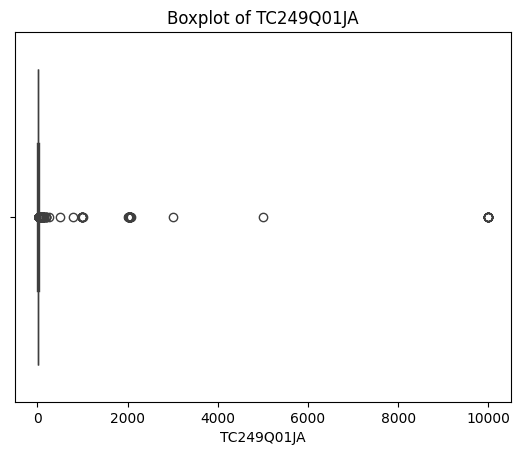

In [ ]:

sns.boxplot(x=target['TC249Q01JA'])
plt.title('Boxplot of TC249Q01JA')
plt.show()

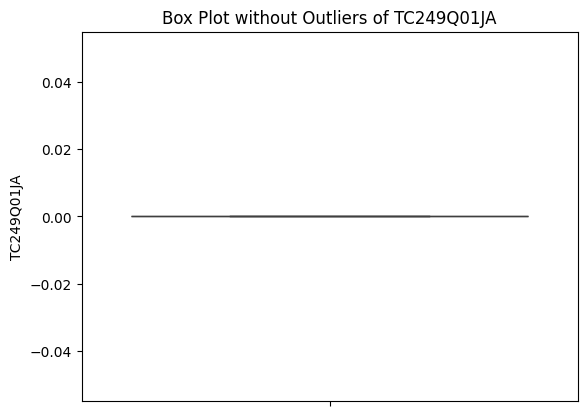

In [12]:
def removal_box_plot(df, column, threshold):
    removed_outliers = df[df[column] <= threshold]

    sns.boxplot(removed_outliers[column])
    plt.title(f'Box Plot without Outliers of {column}')
    plt.show()
    return removed_outliers

threshold_value = 0.12

no_outliers = removal_box_plot(target, 'TC249Q01JA', threshold_value)

In [13]:
Q1 = np.percentile(target['TC249Q01JA'], 25, method='midpoint')
Q3 = np.percentile(target['TC249Q01JA'], 75, method='midpoint')
IQR = Q3 - Q1
print(IQR)

nan


In [14]:
target.to_csv("final_teacher.csv")

Capstone Work

In [ ]:
capstone = pd.read_csv('/content/drive/MyDrive/Colab/select.csv')
#Basic check for rows & columns

print("Dataset shape:", capstone.shape)

print("Number of rows:", capstone.shape[0])
print("Number of columns:", capstone.shape[1])
print(capstone.isna().sum())

missing_placeholders = [-999]
# if NA is better replace "" with np.nan
cap = capstone.replace(missing_placeholders, "")

print(cap.head())

print(cap.isna().sum())

Dataset shape: (1180, 33)
Number of rows: 1180
Number of columns: 33
GPA            0
Classi         0
Age            0
Male           0
PcvdMatch_1    0
PcvdMatch_2    0
PcvdMatch_3    0
BehEng_1       0
BehEng_2       0
BehEng_3       0
BehEng_4       0
CogEn_1        0
CogEn_2        0
CogEn_3        0
CogEn_4        0
CogEn_5        0
CogEn_6        0
CogEn_7        0
CogEn_8        0
CogEn_9        0
CogEn_10       0
ColMot_1       0
ColMot_2       0
ColMot_3       0
ColMot_4       0
ColMot_5       0
ColMot_6       0
ColMot_7       0
ColMot_8       0
ColMot_9       0
ColMot_10      0
ColMot_11      0
ColMot_12      0
dtype: int64
   GPA  Classi Age Male PcvdMatch_1 PcvdMatch_2 PcvdMatch_3 BehEng_1 BehEng_2  \
0  2.0       1  18    0           6           6           6        6        6   
1  2.5       1  18    0           4           5           4        6        6   
2  3.0       1  18    0           4           4           4        7        7   
3  4.0       1  18    0          

In [ ]:
cap.to_csv("capstone.csv")

Model Building